# Пол клиента по транзакциям — поведенческое моделирование

**Транзакции → интерпретируемый поведенческий профиль и поведенческий эмбеддинг клиента → предпочтения
и характеристики** (пол — пример downstream-задачи).

| | ROC AUC | Accuracy |
|---|---|---|
| Кросс-валидация, train+val (2×5 фолдов) | 0.8907 ± 0.0121 | 0.8044 ± 0.0132 |
| **Test**, 1 680 клиентов, 95% CI | **0.898 [0.883; 0.913]** ✓ | **0.811 [0.793; 0.830]** ✓ |
| Требование задания | > 0.88 | > 0.80 |

**Подход.** Поведенческие признаки клиента (профиль покупок по MCC, суммы, время, динамика) → LightGBM;
поведенческий эмбеддинг CoLES (GRU, предобучен без меток) → признак и отдельная дообученная модель;
TabPFN; калиброванный бленд трёх моделей, порог 0.5.

**Основной путь** (10–15 минут): 1. Данные · 2. Поведенческий профиль · 3. Модель · 4. Демонстрация ·
5. Выводы и ограничения

**Приложения:** A. Данные подробно (EDA, время и 00:00:00, суммы и масштаб, MCC, терминалы) ·
B. Надёжность оценки (разбиение, adversarial validation, сила сигнала групп, CV по фолдам) ·
C. Модели изнутри (признаки с метками, архитектура, ключевой код, гиперпараметры и Optuna, сравнение бустингов) ·
D. Профиль подробно (сегменты, соседи по эмбеддингу, SHAP, карточки клиентов)

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
from inspect import getsource

from IPython.display import Code
from sklearn.metrics import roc_auc_score

from gender_pred import cli, cv, data, features, models, plots, sequence
from gender_pred.cv import bootstrap_ci
from gender_pred.data import download_data, labels, load_config, prepare_events

RETRAIN = False  # True — полный пересчёт (~25 мин на GPU); False — финальные модели из artifacts/ (GitHub Release)
cfg = load_config("configs/default.yaml", retrain=RETRAIN)
plots.style()
pd.set_option("display.max_columns", 30, "display.width", 200)

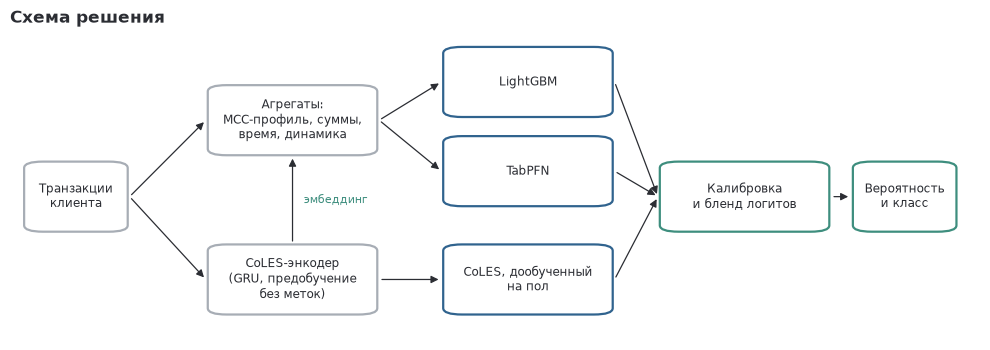

In [2]:
fig = plots.pipeline_schema()

## 1. Данные

**Что за датасет.** Банковские карточные транзакции клиентов с меткой пола — открытый бенчмарк Сбербанка
по предсказанию пола клиента по транзакциям (используется, например, в pytorch-lifestream / CoLES как задача
gender). Версия задания — [`mks-logic/gender_prediction`](https://huggingface.co/datasets/mks-logic/gender_prediction)
на Hugging Face: 8 400 клиентов, разбитых на train / val / test **по клиентам**.

**Постановка.** Классифицируем **клиента**, а не транзакцию: у каждого клиента одна метка пола и история из
десятков–тысяч операций. Всё, что подаётся в модель, — описание клиента целиком (агрегаты по его операциям
или эмбеддинг всей последовательности).

Всё, что касается меток, —
только по train (в приложении B — по train + val, как в кросс-валидации); метки test не используются нигде.

| Колонка | Описание |
|---|---|
| `customer_id` | идентификатор клиента; по нему сделано разбиение на сплиты и агрегация признаков |
| `tr_datetime` | дата и время операции. Даты условные: период начинается 2000-01-01 и длится 457 дней |
| `day` | номер дня от начала периода. В этой версии CSV отдельной колонки нет — день вычисляется из `tr_datetime` при подготовке транзакций (раздел 2) |
| `mcc_code` | MCC — код категории продавца (продукты, одежда, авто, АЗС…), перекодирован в номера |
| `tr_type` | тип операции: покупка, снятие наличных, перевод, зачисление и т. д. |
| `amount` | сумма в условных единицах (отмасштабирована). **Знак: < 0 — расход, > 0 — поступление** |
| `term_id` | идентификатор терминала; пропуск (в шаблоне заменяется на −1) — терминал неизвестен |
| `gender` | целевая метка: 0 — женщина, 1 — мужчина; одна на клиента |
| `tr_type_desc`, `mcc_code_desc` | текстовые описания типа операции и MCC; в признаках не используются, только для подписей |
| `gender_desc` | добавляется в `load_dataset` шаблона: метка словами |

In [3]:
download_data(cfg["paths"]["data"])

In [4]:
def load_dataset(splits=["train", "val", "test"], path="data/"):
    dataset = {}
    for split in splits:
        df = pd.read_csv(f"{path}{split}.csv")
        df["term_id"] = df["term_id"].fillna(-1)
        df['gender_desc'] = df.gender.map({0: "женщина", 1: "мужчина"})
        df['tr_datetime'] = pd.to_datetime(df['tr_datetime'], errors='coerce')
        df.sort_values(['customer_id', 'tr_datetime'], inplace=True)
        dataset[split] = df
    return dataset

dataset = load_dataset()

train_df = dataset["train"]
train_df.head(2)

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id,gender,tr_type_desc,mcc_code_desc,gender_desc
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1,1,Оплата услуги. Банкоматы СБ РФ,"Звонки с использованием телефонов, считывающих...",мужчина
1,0,2000-01-02 10:19:29,1,1,56147.89,-1,1,Взнос наличных через АТМ (в своем тер.банке),Финансовые институты — снятие наличности автом...,мужчина


In [5]:
for split in ["train", "test", "val"]:
    print(f"{split.upper()} split: ", dataset[split]["customer_id"].nunique(), " customers")

TRAIN split:  5880  customers
TEST split:  1680  customers
VAL split:  840  customers


In [6]:
data.split_overview(dataset, label_splits=("train", "val"))

,строк,клиентов,начало,конец,дней,доля мужчин
train,2613040,5880,2000-01-01,2001-04-01,457,0.439
val,383675,840,2000-01-01,2001-04-01,457,0.425
test,754368,1680,2000-01-01,2001-04-01,457,—


In [7]:
data.data_quality(train_df).to_frame("train")

,train
строк,2613040
полных дубликатов строк,7658
нераспознанных дат (NaT),0
клиентов с > 1 значением пола,0
|amount|: 99-й перцентиль,1122957.89
|amount|: 99.9-й перцентиль,4941014.7
|amount|: максимум,145984525.17
доля операций с |amount| > 99.9-го перцентиля,0.001


**Ключевые наблюдения** (подробно — в приложениях A и B):
- клиентов в нескольких сплитах нет; test не отличается от train (adversarial validation: AUC 0.495) —
  кросс-валидация на train + val репрезентативна;
- 12% операций — ровно 00:00:00: для части каналов время не передаётся, это «время неизвестно»;
- активность и суммы различаются на порядки, хвосты тяжёлые → доли и логарифмы;
- сильнейший сигнал — **что покупает клиент** (MCC): одна эта группа даёт AUC 0.874,
  остальные группы по отдельности — 0.55–0.67; терминалы почти бесполезны (у медианного — один клиент).

**Наблюдение → решение в пайплайне → чем подтверждено**

| Наблюдение | Решение в пайплайне | Чем подтверждено |
|---|---|---|
| Классификация клиента; разбиение по клиентам, пересечений нет | всё агрегируется до клиента; CV — stratified по клиентам на train + val | `client_overlap` = 0 (прил. B) |
| Test не отличается от train | CV на train + val как оценка качества; test — один раз | adversarial AUC = 0.495 (прил. B) |
| 12% операций в 00:00:00 — время не передаётся для части каналов | флаг `mid`, исключение из часового профиля, доля — отдельный признак | в ~60 000 раз больше соседних секунд, 72% — один тип операции (прил. A) |
| Чёткий недельный цикл, неизвестно, какие дни выходные | 7 долей по `day % 7` вместо флага «выходной» | провалы объёма на днях 1 и 2 (прил. A) |
| Активность различается на порядки | доли вместо счётчиков; log активности; окна 30 / 90 / 180 дней | распределения на лог-шкале (прил. A) |
| Тяжёлые хвосты сумм; суммы = исходные × константа | log(1 + \|amount\|), квантили, отдельно расходы / поступления; без признака «круглая сумма» | максимум ≈ 30 × p99.9; AUC доли круглых ≈ 0.52 (прил. A) |
| Сильнейший перекос — в редких MCC | доли по всем 184 MCC, TF-IDF + логрег, сглаженный target encoding | lift с 95% CI (2.4); AUC группы MCC (прил. B) |
| Один клиент на терминал | только общие статистики терминалов | TE терминалов и граф — в пределах шума по 10 фолдам (прил. A) |
| Профиль трат — главный сигнал, остальное слабее | ставка на MCC-признаки и CoLES; бленд с TabPFN | AUC по группам (прил. B), вклад компонентов (3) |

## 2. Поведенческий профиль

Из транзакций строится профиль клиента: поведенческие признаки (агрегаты по группам), RFM и предпочтения
по категориям покупок. Метки здесь используются только для сравнения групп на train.

### 2.1 Подготовка транзакций

`prepare_events` переводит сырые строки в компактный вид, общий для агрегатов и последовательной модели:
день от начала периода, час и день недели, флаг неизвестного времени, знак и логарифм суммы, терминал
(−1 — неизвестен). Ниже — три операции одного клиента до и после (последняя — со временем 00:00:00).

In [8]:
one = train_df[train_df["customer_id"] == train_df["customer_id"].iloc[0]]
at_midnight = one["tr_datetime"] == one["tr_datetime"].dt.normalize()
rows = pd.concat([one[~at_midnight].head(2), one[at_midnight].head(1)])
rows[["customer_id", "tr_datetime", "mcc_code", "tr_type", "amount", "term_id"]]

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1
1,0,2000-01-02 10:19:29,1,1,56147.89,-1
28,0,2000-01-16 00:00:00,8,6,-6288.56,-1


In [9]:
prepare_events(rows)[["cid", "mcc", "tt", "la", "out", "term", "day", "hour", "dow", "mid"]]

,cid,mcc,tt,la,out,term,day,hour,dow,mid
0,0,0,0,7.717316,True,-1,0,10,0,False
1,0,1,1,10.935762,False,-1,1,10,1,False
2,0,8,6,8.746646,True,-1,15,0,1,True


`la` = log(1 + |amount|), `out` — расход, `day` — номер дня, `hour` / `dow` — час и день недели, `mid` — время
неизвестно (час для таких операций в признаках не учитывается). Для последовательной модели из этих полей
дополнительно строятся знаковая лог-сумма и логарифм интервала до предыдущей операции.

### 2.2 Поведенческие признаки

Энкодер CoLES нужен уже здесь: его поведенческий эмбеддинг входит в признаки. При `RETRAIN = False` энкодер
и финальные модели загружаются из `artifacts/` (архив из GitHub Release), при `True` — обучаются заново.

In [10]:
ctx = cli.build_context(cfg, dataset, log=False)
print(f"устройство: {ctx.device}; клиентов с последовательностями: {len(ctx.seqs.ids)}")

устройство: cuda; клиентов с последовательностями: 8400


Функции шаблона: `generate_features` считает признаки одного сплита (вызывается отдельно на train / val / test),
`fit_predict_proba` обучает модель на train+val и предсказывает test. Обе — тонкие обёртки над пакетом.

In [11]:
def generate_features(df):
    """Агрегаты клиента + эмбеддинг CoLES (index = customer_id); последовательности — в хранилище пакета."""
    X = ctx.features(df)
    y = labels(df).reindex(X.index)
    return X, y


def fit_predict_proba(X_train, y_train, X_val, y_val, X_test):
    """LightGBM + дообученный CoLES + TabPFN, калиброванный бленд; порог 0.5."""
    return cli.fit_predict(ctx, X_train, y_train, X_val, y_val, X_test)

In [12]:
X_train, y_train = generate_features(dataset["train"])
X_train.shape

(5880, 2165)

Признаки без меток — одинаковые колонки на любом сплите: словари MCC и типов операций фиксируются по train.
`raw_` — счётчики операций и сумм по каждому MCC / типу (вход для признаков с метками; в бустинг
напрямую не идут), `emb_` — поведенческий эмбеддинг CoLES (приложения C, D).

In [13]:
features.feature_groups(X_train)

,группа,префикс,признаков,примеры
0,Активность,act_,16,"act_n_tr, act_n_tt, act_gap_mean"
1,Суммы,amt_,31,"amt_out_cnt, amt_out_la_q75, amt_in_la_skew"
2,MCC-профиль,mcc_,408,"mcc_cnt_0, mcc_cnt_136, mcc_sum_88"
3,Типы операций,tt_,148,"tt_cnt_0, tt_cnt_49, tt_sum_24"
4,Время,time_,48,"time_hour_0, time_hour_16, time_dow_sum_1"
5,Терминалы,term_,7,"term_na_share, term_tr_per_term, term_top3_share"
6,Динамика,dyn_,41,"dyn_mcc_cnt_hhi, dyn_out_frac_ewm30, dyn_w30_o..."
7,Счётчики,raw_,442,"raw_mcccnt_0, raw_mcccnt_147, raw_mccsum_110"
8,Эмбеддинги CoLES,emb_,1024,"emb_0, emb_341, emb_682"


**Признаки с метками** — target encoding MCC и типов операций, логрег по TF-IDF профиля покупок и логрег
по эмбеддингу CoLES — считаются только внутри обучения и **out-of-fold**: значение обучающего клиента считает
модель, не видевшая его метку; для новых клиентов (и test) — по статистикам обучения. Подробно и с кодом —
приложение C.

### 2.3 RFM

Классика поведенческой аналитики: **recency** — дней с последней операции до конца периода; **frequency** —
операций и активных дней в месяц; **monetary** — сумма расходов и средний чек. Ниже — распределения по полу
(train) и медианы; карточки отдельных клиентов — в разделе 4 и приложении D.

,"recency, дней",операций в месяц,активных дней в месяц,сумма расходов,средний чек
gender,,,,,
женщины,1.0,21.4,11.7,8192685.2,32755.6
мужчины,1.0,25.3,12.9,12461269.7,43073.1


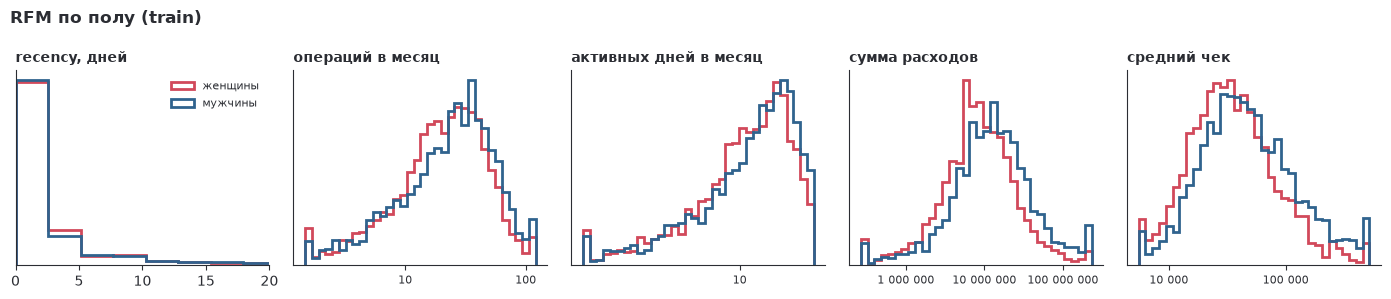

In [14]:
ref = features.CardReference.from_train(train_df)
fig = plots.rfm_by_gender(ref.rfm, labels(train_df))
ref.rfm.groupby(labels(train_df).map({0: "женщины", 1: "мужчины"})).median().round(1)

**Вывод.** Мужчины в среднем чаще платят и тратят больше (выше и средний чек), но распределения сильно
перекрываются: RFM описывает активность, а не предпочтения, и пол различает слабо.

### 2.4 Предпочтения мужчин и женщин

Lift MCC = доля мужчин, пользующихся категорией / доля женщин, с 95% доверительным интервалом
(отношение рисков); только MCC с ≥ 200 клиентами train.

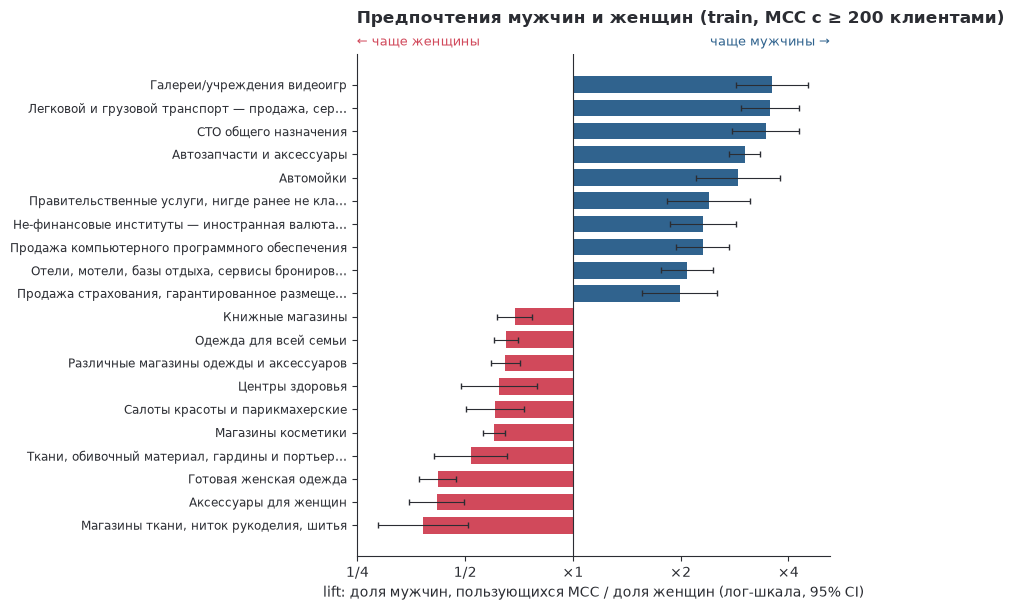

In [15]:
lift = data.mcc_gender_lift(train_df)
fig = plots.mcc_gender_lift(lift)

**Вывод.** Мужчины в 3–4 раза чаще пользуются автосервисом, автозапчастями, автомойками и видеоиграми;
женщины в 2–3 раза чаще — женской одеждой, аксессуарами, тканями и рукоделием, косметикой. Интервалы узкие:
это устойчивые предпочтения, а не шум редких категорий.

## 3. Модель

Три модели смотрят на клиента по-разному: **LightGBM** на поведенческих признаках — сильнейшая одиночная
модель; **TabPFN** на тех же признаках — другой способ обобщения (предобученный трансформер вместо деревьев);
**CoLES**, дообученный на пол, видит порядок и ритм операций. XGBoost вровень с LightGBM, прирост в бленде
в пределах шума — оставили одну модель бустинга ради простоты; CatBoost хуже, вес 0. Финальная модель
зафиксирована до открытия test.

Веса бленда подбираются по out-of-fold предсказаниям: калибровка (Platt) каждой модели, перебор весов
логитов с шагом 0.05 по AUC, общая калибровка, порог 0.5; на CV всё это для фолда — по остальным фолдам.
Устройство моделей, ключевой код, гиперпараметры, Optuna и сравнение бустингов — приложение C;
устойчивость по фолдам — приложение B.

In [16]:
from gender_pred.cv import model_summary

with pd.option_context("display.max_colwidth", None):
    display(model_summary("results"))

,что это,на чём учится,CV ROC AUC,CV accuracy,в финале
модель,,,,,
LightGBM,"градиентный бустинг, основная модель","агрегаты клиента + признаки с метками (OOF), в т. ч. логрег по эмбеддингу CoLES",0.8900 ± 0.0119,0.8028 ± 0.0127,"да, вес 0.70"
TabPFN v2,"предобученный трансформер для таблиц, предсказывает без обучения деревьев","300 признаков, отобранных по gain LightGBM внутри обучения",0.8874 ± 0.0124,0.8001 ± 0.0132,"да, вес 0.20"
"CoLES, дообученный","GRU-энкодер, предобученный контрастно без меток, + голова на пол",последовательность последних 1 200 транзакций клиента,0.8664 ± 0.0135,0.7815 ± 0.0144,"да, вес 0.10"
XGBoost,градиентный бустинг,"та же матрица и те же фолды, что у LightGBM",0.8898 ± 0.0126,0.8042 ± 0.0131,"нет: вровень с LightGBM (AUC -0.0001 ± 0.0018 к LightGBM, лучше в 7/10 фолдов); прирост в бленде +0.00003 ± 0.0006 AUC — в пределах шума, оставили одну модель бустинга ради простоты"
CatBoost,градиентный бустинг (симметричные деревья),"та же матрица и те же фолды, что у LightGBM",0.8853 ± 0.0129,0.7972 ± 0.0161,"нет: хуже LightGBM (AUC -0.0047 ± 0.0027 к LightGBM, лучше в 0/10 фолдов); в бленде вес 0"
Бленд = итог,калиброванная взвешенная сумма логитов трёх моделей,"out-of-fold предсказания LightGBM, TabPFN и CoLES",0.8907 ± 0.0121,0.8044 ± 0.0132,"итог, порог 0.5"


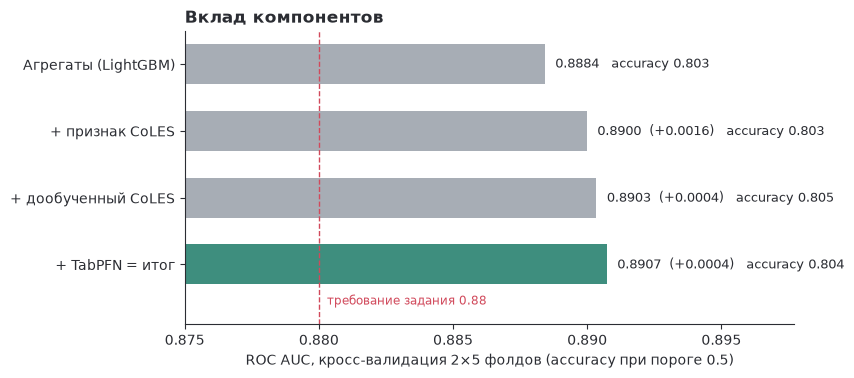

In [17]:
fig = plots.component_contribution(cfg)

**Вывод.** Поведенческие признаки с LightGBM дают 0.8884; признак CoLES и дообученный энкодер добавляют
сигнал о порядке операций, которого нет в агрегатах; TabPFN в одиночку почти на уровне LightGBM и добавляет
разнообразия. Итог — **0.8907** (accuracy 0.804).
Веса бленда: gbm 0.70, seq 0.10, tabpfn 0.20. Каждое добавление проверялось парным сравнением по
10 фолдам.

### Бейзлайн задания

In [18]:
def baseline_aggregation(df):
    tx_stats = df.groupby('customer_id').agg({
        'amount': ['count', 'sum'],
        'mcc_code': pd.Series.nunique,
        'tr_type': pd.Series.nunique,
    })
    tx_stats.columns = [f'base_{k}_{stat}' for k, stat in tx_stats.columns]
    tx_stats.reset_index(inplace=True)

    target = df[['customer_id', 'gender']].drop_duplicates()
    features = tx_stats.merge(target, on='customer_id', how='left')

    X = features.drop(columns=['customer_id', 'gender'])
    y = features['gender']

    return X, y

X_train, y_train = baseline_aggregation(dataset["train"])
X_test, y_test = baseline_aggregation(dataset["test"])
X_val, y_val = baseline_aggregation(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, average_precision_score,
    precision_score, recall_score
)

def eval(y_val, y_pred, y_pred_proba):
    auc = roc_auc_score(y_val, y_pred_proba)
    acc = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)

    return {
        "auc_score": auc,
        "accuracy_score": acc,
        "precision_score": precision,
        "recall_score": recall
    }

def fit_predict_rf(X_train, y_train, X_val, y_val, X_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)

    return y_pred_proba, y_pred

y_pred_proba, y_pred = fit_predict_rf(X_train, y_train, X_val, y_val, X_test)
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.5737087280045527,
 'accuracy_score': 0.5577380952380953,
 'precision_score': 0.5238095238095238,
 'recall_score': 0.4269081500646831}

### Итог на test

Ячейка шаблона: признаки считаются на каждом сплите отдельно, модель обучается на train+val, test только
предсказывается. При `RETRAIN = False` загружаются финальные модели из `artifacts/`.

In [20]:
# Feature engineering
X_train, y_train = generate_features(dataset["train"])
X_test, y_test = generate_features(dataset["test"])
X_val, y_val = generate_features(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

# Model training and prediction
y_pred_proba, y_pred = fit_predict_proba(X_train, y_train, X_val, y_val, X_test)

# Evaluation
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.8979020440415284,
 'accuracy_score': 0.8113095238095238,
 'precision_score': 0.8343108504398827,
 'recall_score': 0.7360931435963778}

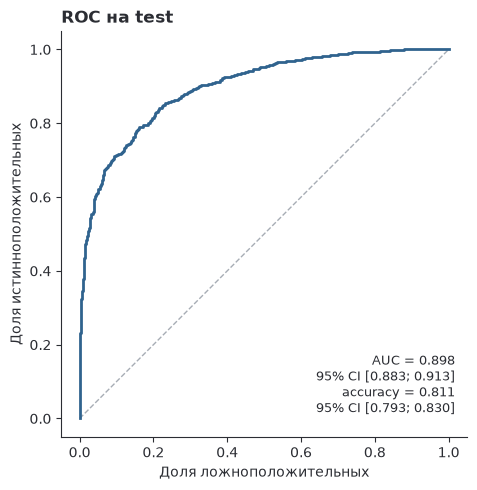

In [21]:
m = bootstrap_ci(y_test.to_numpy(), y_pred_proba, threshold=0.5, n=cfg["report"]["bootstrap"])
pd.DataFrame({"gender": y_test.to_numpy(), "proba": y_pred_proba}, index=y_test.index).to_parquet(
    "results/test_predictions.parquet")
fig = plots.roc_test(cfg)

**Вывод.** На test AUC = **0.8979** (95% CI 0.883–0.913),
accuracy = **0.8113** (95% CI 0.793–0.830):
требования ✓ AUC > 0.88 и ✓ accuracy > 0.80.
Ширина интервалов (±0.015 по AUC на 1 680 клиентах) больше, чем
разница между сильными вариантами модели, поэтому решения принимались только по кросс-валидации.

## 4. Демонстрация: клиенты test

Готовая модель на трёх клиентах test: уверенно верный, самый неуверенный и самая уверенная ошибка. Для каждого —
карточка (RFM, предпочтения покупок, часы и дни недели против среднего клиента) и вклад топ-8 признаков
в предсказание LightGBM; в таблице — вероятности трёх моделей, бленда и истинный пол.

In [22]:
model = cv.GenderModel.load(ctx.artifacts / "model", cfg, ctx.device, ctx.seqs)
names = {f: cli.feature_label(f, cli._mcc_desc(train_df)) for f in [*model.columns_, "bias"]}
proba = model.explain(X_test, ctx.seqs)
examples = cv.pick_examples(y_test, proba["blend"])
table = proba.loc[list(examples.values())].round(3).assign(
    истина=y_test.loc[list(examples.values())].map({0: "женщина", 1: "мужчина"}).to_numpy())
table.index = [f"{k} ({v})" for k, v in examples.items()]
table.rename(columns={"gbm": "LightGBM", "seq": "CoLES", "tabpfn": "TabPFN", "blend": "бленд"})

,LightGBM,CoLES,TabPFN,бленд,истина
уверенно верно: женщина (3936),0.005,0.003,0.010,0.005,женщина
уверенно верно: мужчина (487),0.992,0.984,0.989,0.992,мужчина
неуверенно (7967),0.545,0.550,0.316,0.500,мужчина
ошибка (4210),0.024,0.037,0.025,0.023,мужчина


In [23]:
contrib_test = model.gbm_contributions(model.matrix(X_test.loc[list(examples.values())]))


def show_client(case):
    c = examples[case]
    card = features.client_card(dataset["test"], c, ref)
    plots.client_card(card, ref, f"{case}: клиент {c}, P(мужчина) = {proba.loc[c, 'blend']:.3f}",
                      contrib=contrib_test.loc[c], labels=names)
    plt.show()

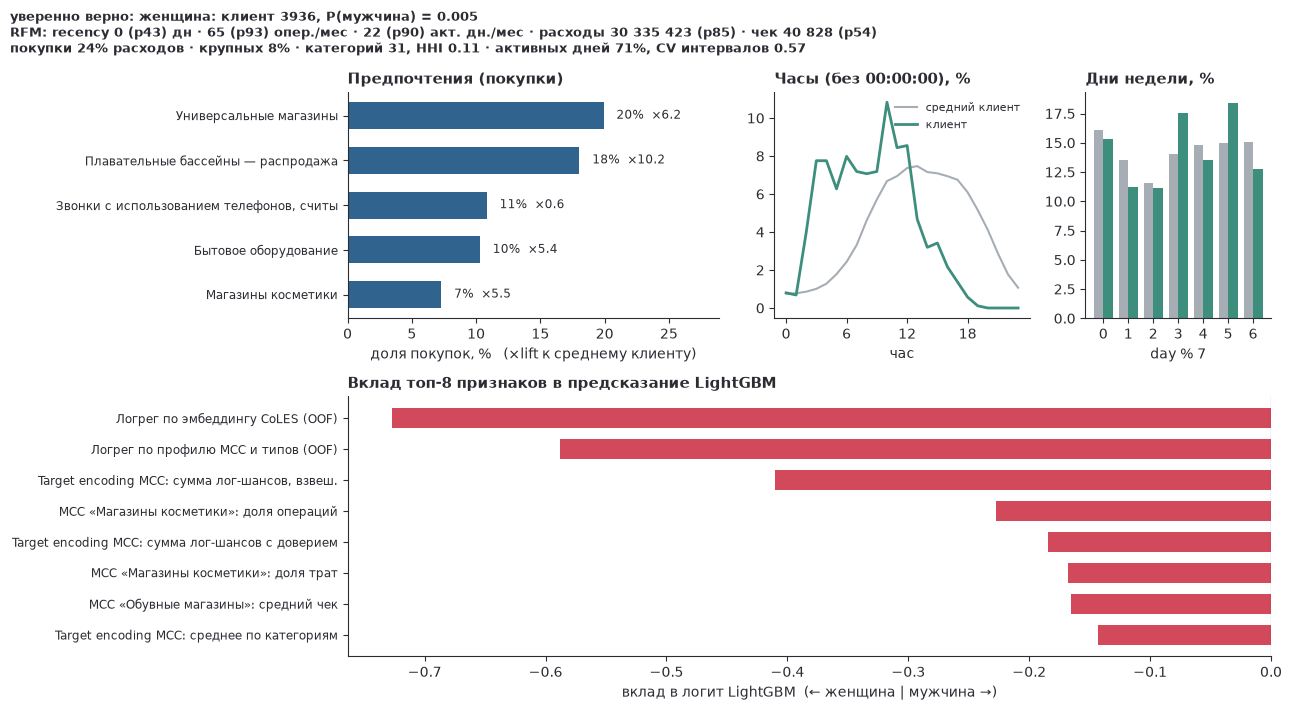

In [24]:
show_client("уверенно верно: женщина")

**Вывод.** «Женский» профиль покупок (универсальные магазины, бассейны, косметика) и эмбеддинг
единодушны: все три модели дают < 1%.

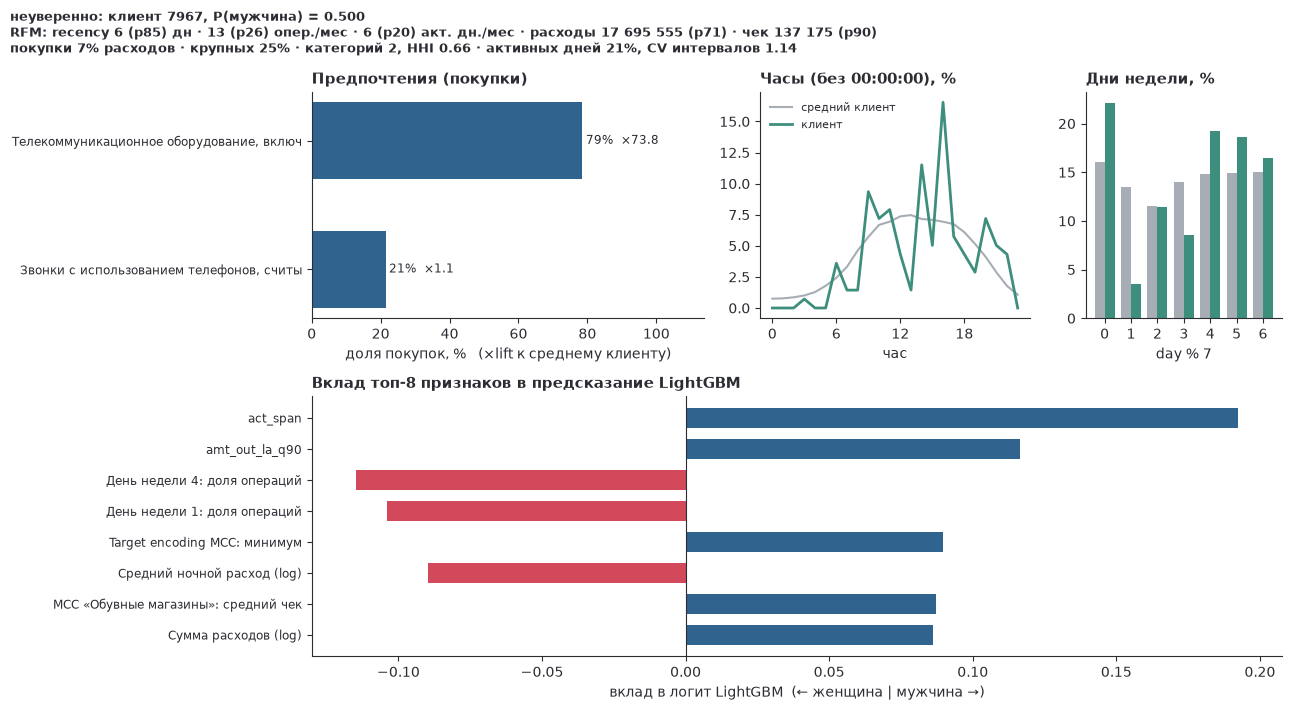

In [25]:
show_client("неуверенно")

**Вывод.** Покупок почти нет (кроме связи 83% расходов — наличные), предпочтения не видны: модели
расходятся (TabPFN 0.32 против 0.55 у LightGBM и CoLES), бленд — ровно на пороге.

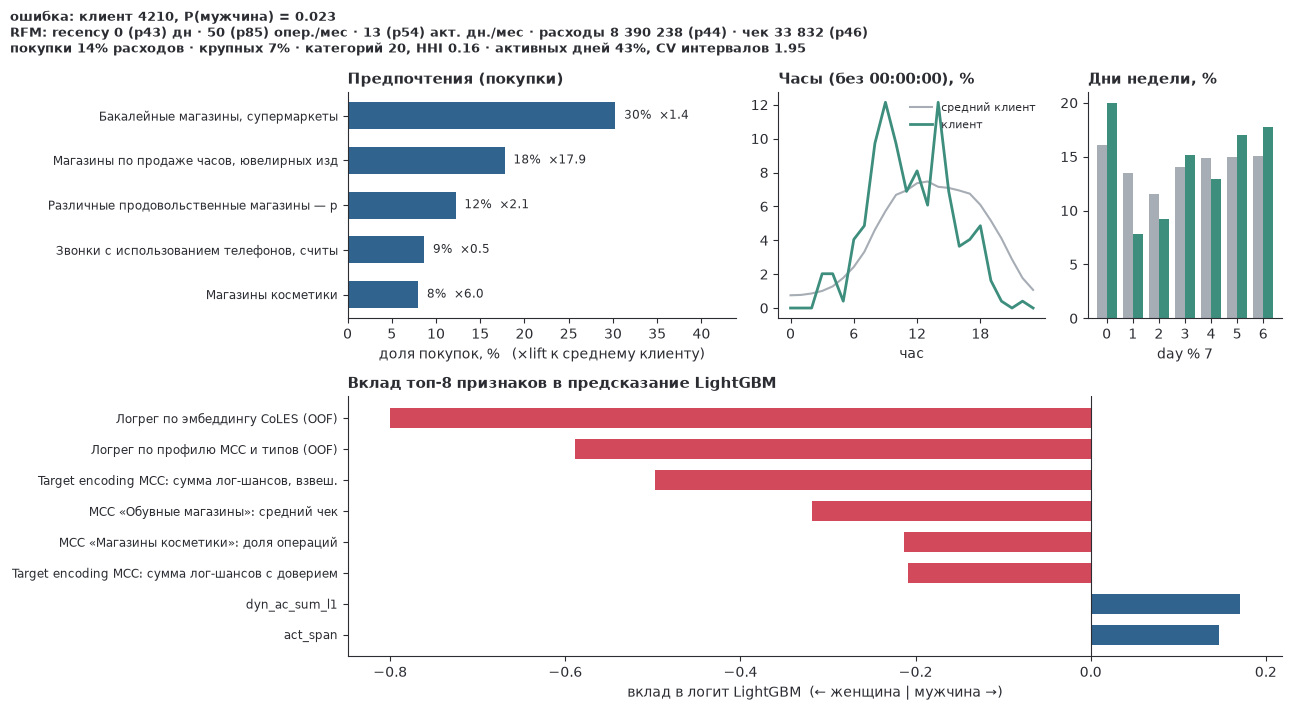

In [26]:
show_client("ошибка")

**Вывод.** Мужчина с «женским» профилем покупок (ювелирные изделия ×18, косметика ×6 к среднему) —
возможно, подарки или общая карта семьи; все модели уверенно ошибаются. Такие клиенты — предел для любой
модели по транзакциям, а не дефект конкретной.

## 5. Выводы и ограничения

- **Поведенческие признаки** решают задачу: главный сигнал — что покупает клиент (профиль MCC; одна группа —
  AUC 0.874), остальное добавляет ≈ 0.017.
- **Поведенческий эмбеддинг CoLES**, обученный без меток, — содержательный профиль: соседи по нему похожи
  покупками, linear probe на пол даёт AUC 0.860; в бленде он добавляет качество к агрегатам.
- **Калиброванный бленд** даёт честные вероятности, поэтому порог 0.5 оптимален для accuracy без подбора на test.
- Пол — пример **downstream-задачи**: тот же профиль и эмбеддинг переиспользуются для других характеристик
  и предпочтений (возраст, доход, склонность к категориям) без новой инженерии признаков.
- Test открывался один раз, на зафиксированной модели: AUC 0.8979, accuracy 0.8113.

**Ограничения.**
- Разбиение по **клиентам**, а не по времени: все сплиты покрывают один период. Для продакшена нужна
  **out-of-time валидация** (обучение на ранних месяцах, проверка на поздних) и **мониторинг дрейфа** —
  PSI по ключевым признакам (доли MCC, RFM, логиты моделей) и по распределению скоров.
- Test (1 680 клиентов) шумный: 95% интервал AUC ≈ ±0.015 — шире различий между сильными вариантами модели.
- Запас по accuracy небольшой: на CV 0.804, в 4 из 10 фолдов ниже 0.80.
- Есть клиенты, чьи покупки «принадлежат» другому полу (подарки, общая карта семьи) — предел для любой
  модели по транзакциям.

**Проверено и не вошло:** target encoding по терминалам и граф клиент–терминал, XGBoost и CatBoost,
тюнинг Optuna, дополнительные статистики концентрации и ритма трат — прирост в пределах шума фолдов.

## Приложение A. Данные подробно

Каждый блок: вопрос → код → вывод → решение для пайплайна. Только train.

### A.1 Обзор и качество

In [27]:
train_df.info(memory_usage="deep", show_counts=True)

<class 'pandas.DataFrame'>
Index: 2613040 entries, 0 to 2613039
Data columns (total 10 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   customer_id    2613040 non-null  int64         
 1   tr_datetime    2613040 non-null  datetime64[us]
 2   mcc_code       2613040 non-null  int64         
 3   tr_type        2613040 non-null  int64         
 4   amount         2613040 non-null  float64       
 5   term_id        2613040 non-null  object        
 6   gender         2613040 non-null  int64         
 7   tr_type_desc   2612068 non-null  str           
 8   mcc_code_desc  2613040 non-null  str           
 9   gender_desc    2613040 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(4), object(1), str(3)
memory usage: 838.1 MB


In [28]:
data.category_overview(train_df).to_frame("train")

,train
уникальных MCC,184
уникальных tr_type,74
уникальных терминалов,245165
"клиентов на терминал, медиана",1
доля операций без терминала,0.406
доля расходов (amount < 0),0.82
доля поступлений (amount > 0),0.18


In [29]:
train_df["amount"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).to_frame("amount (train)").T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
amount (train),2613040.0,-21616.479498,601617.050289,-1.459845e+08,-3368873.66,-898366.31,-5617.04,631067.7331,3368873.66,1.459845e+08


In [30]:
train_df.isna().sum().to_frame("пропусков").T

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id,gender,tr_type_desc,mcc_code_desc,gender_desc
пропусков,0,0,0,0,0,0,0,972,0,0


**Вывод.** 2.6 млн операций у 5 880 клиентов train; мужчин 44% (в val 43%) — классы почти сбалансированы.
Данные чистые: все даты распознаются, у каждого клиента одно значение пола, пропуски — только в текстовом
описании части типов операций. 0.3% строк — полные дубликаты (вероятно, реальные повторные операции при
округлённом времени). Суммы с тяжёлыми хвостами: максимум в ~30 раз больше 99.9-го перцентиля.

**Решение.** Метки берутся на уровне клиента (`labels`: одна на клиента); дубликаты не удаляются — они
одинаково обрабатываются на всех сплитах; суммы используются в виде log(1 + |amount|) и квантилей, а не сырыми;
порог 0.5 и accuracy адекватны при балансе 44 / 56.

### A.2 Время и аномалия 00:00:00

**Вопрос:** покрывают ли данные весь период, есть ли недельный цикл и аномалии во времени, различается ли
время операций у мужчин и женщин, какова длина истории клиента?

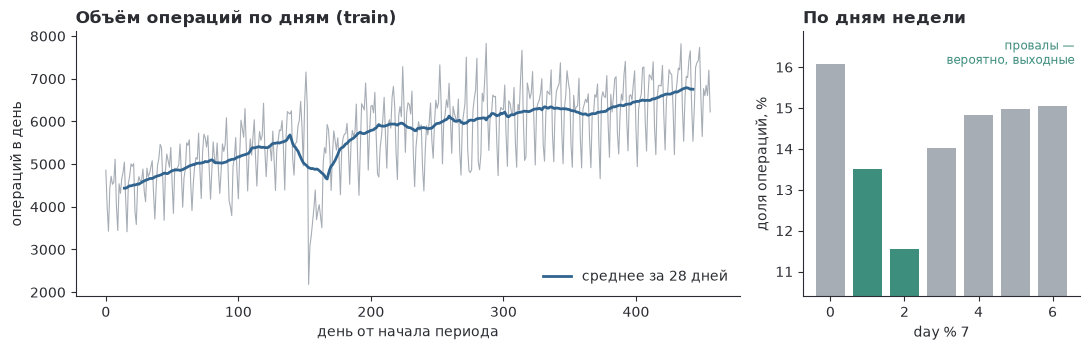

In [31]:
fig = plots.time_volume(train_df)

Период покрыт полностью (457 дней), объём растёт со временем; около 150-го дня — кратковременный провал
(вероятно, сбой выгрузки). Недельный цикл чёткий: по `day % 7` два дня с провалом объёма (1 и 2) —
вероятно, выходные. Поэтому день недели в признаках — как 7 отдельных долей (`time_dow_*`), без
предположения, какие дни выходные.

In [32]:
summary, by_type = data.midnight_check(train_df)
display(summary.to_frame("train"))
by_type

,train
операций в 00:00:00,316243
в среднем за секунду 00:00:01–00:00:59,4.9
в среднем за секунду суток,30.2
доля операций в 00:00:00,0.121


,desc,операций,доля_00,доля всех 00:00:00
tr_type,,,,
6,Покупка. POS ТУ Россия,361872,0.629,0.720
9,Покупка. ТУ Россия,44599,0.737,0.104
25,Покупка. Зарубеж. ТУ,33919,0.936,0.100
7,Возврат покупки. POS ТУ Россия,7677,0.802,0.019
26,Покупка. POS Зарубеж. ТУ,8831,0.690,0.019


**Аномалия 00:00:00.** На ровно 00:00:00 приходится 12% операций — в десятки тысяч раз больше, чем на любую соседнюю
секунду (~5 операций). 72% таких операций — один тип «Покупка. POS ТУ Россия» (и родственные «ТУ» / зарубежные): для этих
каналов время просто не передаётся. Значит, 00:00:00 — это «время неизвестно», а не полночь.

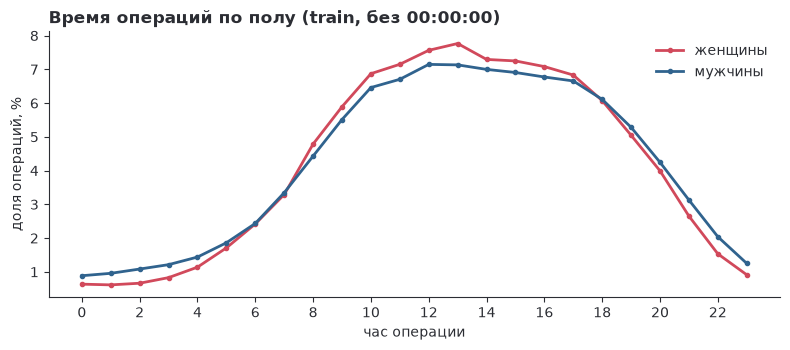

In [33]:
fig = plots.hourly_by_gender(train_df)

In [34]:
data.client_activity(train_df)["длина истории, дней"].describe().round(1).to_frame("train").T

,count,mean,std,min,25%,50%,75%,max
train,5880.0,428.1,68.3,1.0,441.0,453.0,456.0,457.0


**Вывод.** У мужчин больше операций вечером и ночью, у женщин — днём: различие небольшое, но стабильное.
У большинства клиентов история охватывает почти весь период (медиана 453 дня из 457).

**Решение.** Флаг `mid` (время неизвестно): такие операции исключаются из часового профиля, а их доля —
отдельный признак `time_midnight_share`. Часовой профиль — доли по 24 часам, ночь / вечер, циклические
sin / cos. Поскольку истории почти одинаково длинные, окна «последние 30 / 90 / 180 дней» сравнимы между
клиентами.

### A.3 Активность

**Вопрос:** насколько клиенты различаются по активности и связана ли она с полом?

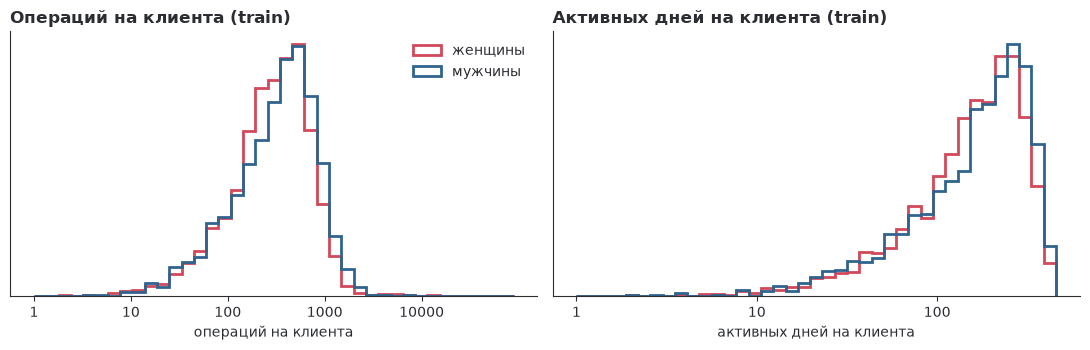

In [35]:
fig = plots.activity_by_gender(train_df)

In [36]:
act = data.client_activity(train_df).join(labels(train_df).map({0: "женщины", 1: "мужчины"}).rename("пол"))
act.groupby("пол")[["операций", "активных дней"]].median()

,операций,активных дней
пол,,
женщины,306.0,166.0
мужчины,356.0,181.0


**Вывод.** Активность различается на порядки (от одной операции до десятков тысяч, медиана ~325), поэтому
шкала логарифмическая. Мужчины чуть активнее (больше операций и активных дней), но распределения сильно
перекрываются — сам по себе объём слабый признак.

**Решение.** Признаки активности логарифмируются, а профили (MCC, типы, часы) считаются как **доли**,
а не счётчики — иначе они в первую очередь отражали бы объём, а не структуру трат. Для последовательной модели
берутся последние 1 200 операций — это вся история у 96% клиентов.

### A.4 Суммы и масштаб

**Вопрос:** различаются ли суммы у мужчин и женщин, отдельно для расходов и поступлений; что известно
о масштабировании сумм?

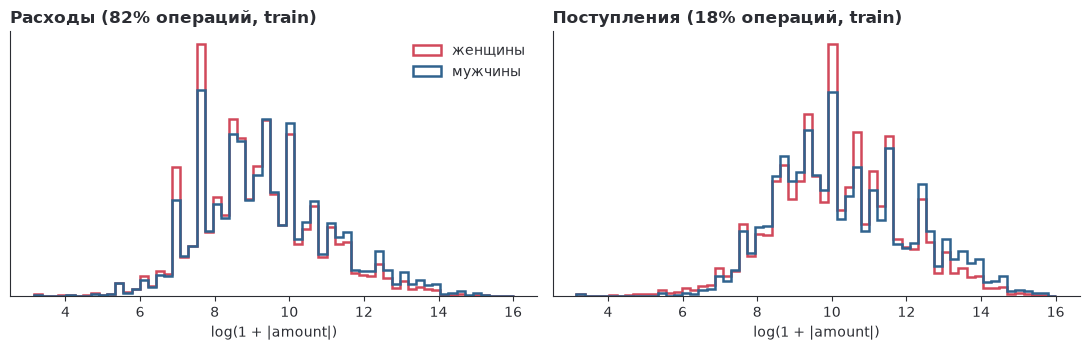

In [37]:
fig = plots.amounts_by_gender(train_df)

In [38]:
unit, in_units = data.amount_scale(train_df)
print(f"самая частая |amount| = {unit}; |amount| в этих единицах (топ-12):")
in_units.to_frame().T

самая частая |amount| = 2245.92; |amount| в этих единицах (топ-12):


amount,1.0,10.0,5.0,0.5,2.0,20.0,3.0,30.0,50.0,40.0,100.0,4.0
операций,161214,101500,92706,80873,74688,61565,53259,49310,48174,31737,31423,30842


In [39]:
rs = data.round_share(train_df, unit)
y_tr = labels(train_df)
print(f"доля операций с целым числом единиц: {(rs * train_df.groupby('customer_id').size()).sum() / len(train_df):.1%}")
print(f"AUC доли «круглых» операций клиента как единственного признака (train): {roc_auc_score(y_tr, rs.reindex(y_tr.index)):.3f}")

доля операций с целым числом единиц: 42.5%
AUC доли «круглых» операций клиента как единственного признака (train): 0.524


**Вывод.** Распределения «гребенчатые» — много типовых сумм. У мужчин чаще крупные расходы и поступления,
у женщин — пики на отдельных типовых суммах. **Масштабирование:** суммы — это исходные суммы, умноженные
на константу (самая частая |amount| ≈ 2245.92 соответствует «1 единице»): в этих единицах значения 1, 10, 5,
0.5, 2, 20, …, и 42.5% операций — целое число единиц. То есть «круглые» суммы восстановимы, но доля
круглых операций клиента сама по себе почти не связана с полом (AUC ≈ 0.52).

**Решение.** Суммы — отдельно для расходов и поступлений (log, квантили, средний чек по MCC, ночной / дневной
расход). Признака «круглая сумма» в модели нет: сигнал слабый (AUC ≈ 0.52); это кандидат в «что дальше»,
а не потеря качества.

### A.5 MCC и tr_type

**Вопрос:** сколько категорий реально важны, где сильнее всего перекос по полу и насколько MCC и тип операции дублируют друг друга?

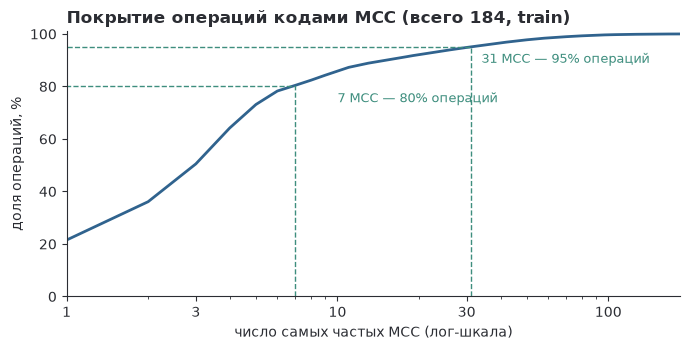

In [40]:
fig = plots.mcc_coverage(train_df)

Семь самых частых MCC покрывают 80% операций, 31 — 95%; остальные ~150 кодов редкие, но именно
в редких (автосервис, женская одежда, рукоделие) — самый сильный перекос по полу (lift — в разделе 2.4).

In [41]:
def plot_top_counts(series, top_n=20, xlabel="Count", ylabel=""):
    counts = series.value_counts()
    top_items = counts.nlargest(top_n)
    plt.figure(figsize=(8,6))
    plt.barh(top_items.index, top_items.values)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

In [42]:
data.mcc_trtype_link(train_df).to_frame("train")

,train
"типов операций на MCC, медиана",4
"MCC на тип операции, медиана",1
доля операций с основным типом своего MCC,0.735
доля операций с основным MCC своего типа,0.74


**Вывод.** Перекос по полу сильный и интерпретируемый: «Галереи/учреждения видеоигр» — доля мужчин на
30 п.п. выше средней, «Магазины ткани, ниток рукоделия, шитья» — на 21 п.п. ниже;
(раздел 2.4: MCC с ≥ 200 клиентами, 95% интервалы не пересекают единицу). MCC и тип операции связаны,
но не дублируют друг друга: у MCC обычно несколько типов операций (медиана 4), у типа операции обычно один MCC.

**Решение.** Профиль трат по MCC — главная группа признаков: доли операций и трат по всем 184 кодам (а не
только частым — сигнал в редких), средний чек по 40 самым частым, TF-IDF + логрег и сглаженный target encoding
(редкие коды стягиваются к среднему). Профиль `tr_type` — отдельная группа того же устройства.

### A.6 Терминалы

**Вопрос:** можно ли извлечь сигнал из терминалов — сколько клиентов на терминал и пересекаются ли терминалы
train и test? (Без меток test.)

In [43]:
data.terminal_overview(train_df, dataset["test"]).to_frame("значение")

,значение
терминалов в train,245165
"клиентов на терминал, медиана",1
доля терминалов с одним клиентом,0.698
доля операций test на терминалах из train,0.704
доля клиентов test с хотя бы одним терминалом из train,0.993


**Вывод.** Терминалов 245 тыс.; у медианного терминала **один клиент**, 70% терминалов встречаются у одного
клиента. 99% клиентов test хотя бы раз платили в терминалах из train, но общие терминалы — это в основном крупные
сети (у четверти таких операций терминал с > 1 600 клиентами обоих полов): о поле они почти ничего не говорят. 41% операций вообще без терминала.

**Решение.** Терминалы — слабая группа из нескольких статистик без меток (доля операций без терминала,
операций на терминал, концентрация). Target encoding терминалов и граф клиент–терминал проверены парным
сравнением по 10 фолдам — прирост в пределах шума, в модель не вошли.

## Приложение B. Надёжность оценки

### B.1 Корректность разбиения

**Вопрос:** нет ли клиентов, попавших в несколько сплитов, и похож ли test на train? Если test заметно
отличается, кросс-валидация на train + val не будет репрезентативной.

In [44]:
data.client_overlap(dataset)

,train,val,test
train,5880,0,0
val,0,840,0
test,0,0,1680


**Adversarial validation:** LightGBM учится отличать клиентов train от клиентов test по агрегатам без меток
(5 фолдов). AUC ≈ 0.5 означает, что сплиты неразличимы. Считается в пакете (`cv.adversarial_auc`) и
сохраняется в `results/`.

In [45]:
adv = json.loads(Path("results/adversarial_validation.json").read_text())
print(f"train ({adv['n_a']}) vs test ({adv['n_b']}): AUC = {adv['auc']:.3f} ± {adv['auc_std']:.3f}")
print("самые «различающие» признаки:", ", ".join(adv["top_features"]))

train (5880) vs test (1680): AUC = 0.495 ± 0.017
самые «различающие» признаки: dyn_ac_sum_l30, mcc_la_9, amt_in_la_skew, dyn_w30_out_la_mean, time_hour_8


**Вывод.** Пересечений клиентов нет; adversarial AUC = 0.495 — сплиты неразличимы, сдвига распределения нет. Баланс классов
в train и val одинаков (раздел 1).

**Решение.** Кросс-валидация на train + val (stratified 5-fold × 2 повтора, по клиентам) — надёжная оценка
качества на test; test открывается один раз в конце.

### B.2 Сила сигнала групп признаков

**Вопрос:** какие группы признаков без меток реально несут сигнал о поле? LightGBM обучается на каждой
группе отдельно (5 фолдов на train + val, число итераций — по остальным фолдам); результат посчитан
в пакете (`cv.group_signal`) и сохранён в `results/`.

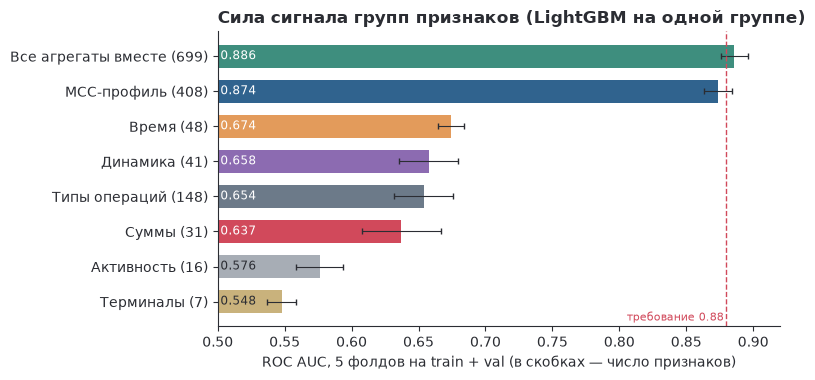

In [46]:
fig = plots.group_signal(cfg)

**Вывод.** Одна группа MCC-профиля даёт AUC 0.874 — почти всё качество: все агрегаты вместе — 0.886. Остальные группы по отдельности слабые: время 0.67, динамика 0.66, типы операций 0.65, суммы 0.64, активность 0.58, терминалы 0.55. Но вместе с MCC они добавляют +0.012, а это больше шума фолдов.

**Решение.** В модель вошли все группы (LightGBM сам отбирает полезное), а основная работа над признаками
пошла в профиль трат: TF-IDF + логрег и target encoding MCC (приложение C) и последовательная модель CoLES
(приложение C), которая видит порядок операций.

### B.3 Кросс-валидация по фолдам

**Вопрос:** насколько устойчива оценка? Метрики итогового бленда на каждом из 10 фолдов (2 повтора × 5)
и AUC каждой модели; калибровка, веса и число деревьев для фолда подобраны по остальным фолдам.

In [47]:
folds = pd.read_csv("results/cv_folds.csv")
print(f"AUC < 0.88: {(folds['auc'] < 0.88).sum()} из {len(folds)} фолдов; "
      f"accuracy < 0.80: {(folds['accuracy'] < 0.80).sum()} из {len(folds)}")
folds.round(4)

AUC < 0.88: 2 из 10 фолдов; accuracy < 0.80: 4 из 10


,repeat,fold,auc,accuracy,auc_gbm,auc_seq,auc_tabpfn
0,0,0,0.8917,0.8095,0.8904,0.8745,0.8870
1,0,1,0.9016,0.8058,0.9017,0.8784,0.8974
2,0,2,0.8838,0.7969,0.8829,0.8633,0.8805
3,0,3,0.9002,0.8147,0.9010,0.8672,0.8980
4,0,4,0.8768,0.7917,0.8760,0.8526,0.8742
5,1,0,0.8737,0.7820,0.8726,0.8445,0.8719
6,1,1,0.8849,0.8043,0.8851,0.8550,0.8795
7,1,2,0.8958,0.8110,0.8947,0.8799,0.8911
8,1,3,0.8857,0.7984,0.8854,0.8615,0.8827
9,1,4,0.9130,0.8296,0.9100,0.8868,0.9120


**Вывод.** Разброс между фолдами (AUC 0.891 ± 0.012) сопоставим с шириной
95% интервала на test (±0.015): на выборке такого размера различия в третьем знаке — шум. Поэтому каждое
изменение модели принималось только по парному сравнению на тех же 10 фолдах.

## Приложение C. Модели изнутри

Признаки с метками, устройство трёх моделей и бленда с ключевым кодом пакета, гиперпараметры и сравнение
бустингов.

### C.1 Признаки подробно

In [48]:
clients = X_train.index[:3]
cols = ["act_n_tr", "amt_out_la_mean", "amt_in_cnt_share", "mcc_cnt_0", "time_night_share",
        "time_midnight_share", "term_na_share", "dyn_mcc_cnt_hhi", "emb_0"]
X_train.loc[clients, cols].round(3)

,act_n_tr,amt_out_la_mean,amt_in_cnt_share,mcc_cnt_0,time_night_share,time_midnight_share,term_na_share,dyn_mcc_cnt_hhi,emb_0
customer_id,,,,,,,,,
0,1046.0,8.439,0.039,0.132,0.082,0.198,0.360,0.233,-0.046
2,132.0,10.080,0.076,0.348,0.288,0.000,0.386,0.442,0.008
3,855.0,9.217,0.062,0.049,0.133,0.013,0.460,0.089,-0.046


**Вывод.** Больше всего gain у групп «линейные модели (TF-IDF, CoLES)» (27%), «MCC-профиль» (19%) и «target encoding» (18%); терминалы почти не используются (1.3%). Вклад признаков по SHAP — в приложении D.

### C.2 Признаки с метками: out-of-fold

Часть признаков использует метку пола: target encoding MCC и типов операций (доля мужчин среди операций
с этим кодом, сглаженная к среднему), логистическая регрессия по TF-IDF профиля трат и логистическая
регрессия по эмбеддингу CoLES. Если посчитать их по всем клиентам и тут же обучить на них бустинг, клиент
«увидит» собственную метку — утечка.

Поэтому они считаются **out-of-fold** и **только внутри обучения**:
- для обучающих клиентов — по внутренним фолдам: значение клиента считает модель, обученная на остальных
  4/5 обучающих клиентов, без его метки;
- для новых клиентов (фолд валидации в CV, test в финале) — по статистикам, посчитанным на всех обучающих.

Test в расчёте не участвует: его метки не используются нигде, а сами признаки для test считаются только
применением уже обученных статистик. Ниже — тот же расчёт на train (в финальной модели — на train+val).

Код: `fit_transform` — out-of-fold значения для обучающих клиентов (внутренние фолды), `transform` —
значения для новых клиентов по статистикам всех обучающих.

In [49]:
display(Code(getsource(features.LabelFeatures.fit_transform), language="python"))
display(Code(getsource(features.LabelFeatures.transform), language="python"))

def fit_transform(self, X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
        yv = y.reindex(X.index).to_numpy()
        folds = StratifiedKFold(self.n_inner, shuffle=True, random_state=self.seed).split(X, yv)
        parts = [self._apply(self._fit_parts(X, yv, a), X, b) for a, b in folds]
        self.parts_ = self._fit_parts(X, yv, np.arange(len(X)))
        return pd.concat(parts).reindex(X.index)

def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        return self._apply(self.parts_, X, np.arange(len(X)))

In [50]:
lf = features.LabelFeatures(cfg["features"], seed=0, n_inner=cfg["cv"]["inner_splits"])
L_train = lf.fit_transform(X_train, y_train)
print(L_train.shape)
L_train.loc[clients, ["te_mcc_wmean", "te_mcc_lo_sum", "te_tt_wmean", "lr_tfidf", "lr_emb"]].round(3)

(5880, 20)


,te_mcc_wmean,te_mcc_lo_sum,te_tt_wmean,lr_tfidf,lr_emb
customer_id,,,,,
0,0.450,0.536,0.439,-0.500,0.184
2,0.439,0.001,0.440,-0.591,0.881
3,0.447,3.773,0.441,0.805,-1.030


In [51]:
pd.Series({c: roc_auc_score(y_train, L_train[c]) for c in ["te_mcc_wmean", "te_tt_wmean", "lr_tfidf", "lr_emb"]},
          name="OOF AUC на train").round(4).to_frame().T

,te_mcc_wmean,te_tt_wmean,lr_tfidf,lr_emb
OOF AUC на train,0.7849,0.5659,0.8615,0.8575


Каждый из этих признаков в одиночку — сильный предиктор, при этом значения out-of-fold, то есть
честные: на новых клиентах они ведут себя так же.

### C.3 Устройство моделей

Финальные модели загружаются из `artifacts/model` (при `RETRAIN = True` — только что обученные). Ниже — что внутри каждой из трёх моделей и бленда.

#### LightGBM

Градиентный бустинг на поведенческих признаках клиента — основная модель (вес 0.70): лучше всех по
отдельности и интерпретируем. Учится на агрегатах и признаках с метками (out-of-fold), включая логрег по
поведенческому эмбеддингу CoLES. Параметры и число деревьев — из загруженной модели.

In [52]:
booster = model.gbm_[0]
keys = ["learning_rate", "num_leaves", "min_data_in_leaf", "feature_fraction", "bagging_fraction",
        "bagging_freq", "lambda_l2", "max_depth"]
pd.Series({**{k: booster.params[k] for k in keys}, "деревьев": booster.num_trees(),
           "признаков": booster.num_feature()}, dtype=object).to_frame("LightGBM").T

,learning_rate,num_leaves,min_data_in_leaf,feature_fraction,bagging_fraction,bagging_freq,lambda_l2,max_depth,деревьев,признаков
LightGBM,0.02,15,30,0.25,0.8,1,10,-1,1043,719


#### CoLES

Поведенческий эмбеддинг: GRU читает последовательность транзакций (эмбеддинги MCC и типа операции,
знаковая лог-сумма, время) и сжимает клиента в вектор. Предобучен без меток контрастно, затем дообучен
на пол — так он видит порядок и ритм операций, которых нет в агрегатах (вес 0.10).

In [53]:
print(ctx.encoder)
n_params = sum(p.numel() for p in ctx.encoder.parameters())
print(f"параметров энкодера: {n_params:,}".replace(",", " "))
print(f"размерность эмбеддинга: {X_train.filter(like='emb_').shape[1]}")

Encoder(
  (e_mcc): NoisyEmbedding(185, 48, padding_idx=0)
  (e_tt): NoisyEmbedding(75, 24, padding_idx=0)
  (e_hour): Embedding(25, 8)
  (e_dow): Embedding(7, 4)
  (gru): GRU(86, 1024, batch_first=True)
)
параметров энкодера: 3 427 996
размерность эмбеддинга: 1024


**Как обучается CoLES.**

Энкодер — GRU над транзакциями (MCC, тип операции, знаковая лог-сумма, час, день недели, интервал между
операциями). Предобучение без меток (CoLES): случайные срезы одного клиента сближаются в пространстве
эмбеддингов, срезы разных клиентов — отталкиваются. Затем энкодер (а) даёт эмбеддинг клиента и (б)
дообучается на пол. Для предобучения используются только клиенты train и val.

Код: нарезка случайных срезов последовательности (`_slice`) и контрастная потеря — все пары срезов одного
клиента сближаются, а `neg_count` ближайших чужих срезов отталкиваются до расстояния `margin`.

In [54]:
display(Code(getsource(sequence._slice), language="python"))
display(Code(getsource(sequence.contrastive_loss), language="python"))

def _slice(rng: np.random.Generator, n: int, lo: int, hi: int) -> tuple[int, int]:
    length = int(rng.integers(min(lo, n), min(hi, n) + 1))
    return int(rng.integers(0, n - length + 1)), length

def contrastive_loss(z: torch.Tensor, labels: torch.Tensor, margin: float, neg_count: int) -> torch.Tensor:
    """Позитивы — все пары срезов одного клиента, негативы — ``neg_count`` ближайших чужих на якорь."""
    z = F.normalize(z, dim=1)
    d = (z[:, None] - z[None]).pow(2).sum(-1).clamp(min=1e-12).sqrt()
    same = labels[:, None] == labels[None]
    pos = d[torch.triu(same, diagonal=1)].pow(2)
    hard = d.masked_fill(same, float("inf")).topk(neg_count, dim=1, largest=False).values
    neg = F.relu(margin - hard).pow(2).flatten()
    return torch.cat([pos, neg]).sum()

In [55]:
enc = cfg["sequence"]["encoder"]
emb = X_train.filter(like="emb_")
print(f"конфигурация энкодера: {enc}")
print(f"эмбеддинг клиента: {emb.shape[1]} чисел; матрица train: {emb.shape}")

конфигурация энкодера: {'hidden': 1024, 'mcc_dim': 48, 'tr_type_dim': 24, 'use_time': True, 'emb_noise': 0.003}
эмбеддинг клиента: 1024 чисел; матрица train: (5880, 1024)


In [56]:
cv_models = pd.read_csv("results/cv_models.csv").set_index("model")
cv_models.loc[[i for i in cv_models.index if "CoLES" in i]].round(4)

,auc,auc_std,accuracy,accuracy_std
model,,,,
"Эмбеддинг CoLES (1024), логрег",0.8599,0.0145,0.7767,0.0166
"LightGBM, агрегаты + признак CoLES",0.8900,0.0119,0.8028,0.0127
"CoLES, дообученный на пол",0.8664,0.0135,0.7815,0.0144


**Вывод.** Эмбеддинг CoLES с логистической регрессией даёт на кросс-валидации AUC 0.860,
дообученный на пол энкодер — 0.866: меньше, чем агрегаты с LightGBM (0.888), но сигнал
частично независимый (порядок и ритм операций), и в бленде он стабильно добавляет качество (раздел 3).
В двумерной проекции (UMAP) пол визуально не разделяется — сигнал распределён по многим измерениям,
поэтому проекцию не показываем.

#### TabPFN v2

Предобученный трансформер для табличных данных: «обучение» — это подача обучающей выборки в контекст,
предсказание — один проход сети. Ошибается иначе, чем деревья, поэтому полезен в бленде (вес 0.20).
Работает на 300 признаках, отобранных по gain LightGBM внутри обучения.

In [57]:
X_fit = model.tabpfn_.X_fit_
print(f"контекст TabPFN: {X_fit.shape[0]} клиентов × {X_fit.shape[1]} признаков")
print("первые 10 признаков:", ", ".join(model.tabpfn_.columns_[:10]))

контекст TabPFN: 6720 клиентов × 300 признаков
первые 10 признаков: lr_emb, lr_tfidf, te_mcc_wlo_sum, te_mcc_mean, te_mcc_lo_mean, te_mcc_conf_lo_sum, te_mcc_wmean, te_mcc_lo_sum, mcc_cnt_49, mcc_la_10


#### Бленд

Каждая модель калибруется по out-of-fold логитам (Platt: logit → a·logit + b), калиброванные логиты
складываются с весами, затем итоговая калибровка; порог 0.5. Параметры финального бленда:

In [58]:
model.blend_.describe(model.components).round(4)

,a,b,вес
шаг,,,
Platt: gbm,0.9398,0.0066,0.7
Platt: seq,0.9462,0.0921,0.1
Platt: tabpfn,0.8617,-0.0762,0.2
итоговый Platt,1.0311,0.0087,NaN


Код бленда: Platt для каждого компонента → взвешенная сумма калиброванных логитов (веса — на симплексе
с шагом 0.05 по AUC) → итоговый Platt. Работает построчно, поэтому применим к test без информации о нём.

In [59]:
display(Code(getsource(models.LogitBlend), language="python"))

class LogitBlend:
    """Калиброванный бленд: Platt для каждого компонента -> взвешенная сумма логитов -> итоговый Platt.

    Веса — на симплексе с шагом ``step`` по AUC. Работает построчно, поэтому применим к test без
    информации о составе test (в отличие от рангового бленда).
    """

    def __init__(self, step: float = 0.05):
        self.step = step

    def _calibrated(self, Z: np.ndarray) -> np.ndarray:
        return np.column_stack([pl.decision_function(Z[:, [i]]) for i, pl in enumerate(self.platt_)])

    def fit(self, Z: np.ndarray, y: np.ndarray) -> LogitBlend:
        self.platt_ = [LogisticRegression(C=1e6, max_iter=1000).fit(Z[:, [i]], y) for i in range(Z.shape[1])]
        C = self._calibrated(Z)
        self.weights_ = max(_simplex(Z.shape[1], self.step), key=lambda w: roc_auc_score(y, C @ w))
        self.final_ = LogisticRegression(C=1e6, max_iter=1000).fit((C @ self.weights_)[:, None], y)
        return self

    def predict_proba(self, Z: np.ndarray) -> np.ndarray:
        return self.final_.predict_proba((self._calibrated(Z) @ self.weights_)[:, None])[:, 1]

    def component_proba(self, Z: np.ndarray) -> np.ndarray:
        """Откалиброванные вероятности каждого компонента по отдельности."""
        return 1 / (1 + np.exp(-self._calibrated(Z)))

    def describe(self, names: list[str]) -> pd.DataFrame:
        """Параметры калибровки (logit -> a·logit + b) и веса компонентов, итоговая калибровка."""
        rows = [
            {"шаг": f"Platt: {n}", "a": p.coef_[0, 0], "b": p.intercept_[0], "вес": w}
            for n, p, w in zip(names, self.platt_, self.weights_)
        ]
        rows.append({"шаг": "итоговый Platt", "a": self.final_.coef_[0, 0], "b": self.final_.intercept_[0]})
        return pd.DataFrame(rows).set_index("шаг")

    def to_dict(self) -> dict:
        return {
            "weights": self.weights_.tolist(),
            "platt": [[float(p.coef_[0, 0]), float(p.intercept_[0])] for p in self.platt_],
            "final": [float(self.final_.coef_[0, 0]), float(self.final_.intercept_[0])],
        }

    @classmethod
    def from_dict(cls, d: dict) -> LogitBlend:
        def lr(coef: float, icpt: float) -> LogisticRegression:
            m = LogisticRegression()
            m.coef_, m.intercept_, m.classes_ = np.array([[coef]]), np.array([icpt]), np.array([0, 1])
            return m

        b = cls()
        b.weights_ = np.array(d["weights"])
        b.platt_ = [lr(*p) for p in d["platt"]]
        b.final_ = lr(*d["final"])
        return b

### C.4 Гиперпараметры и Optuna

Все гиперпараметры, сиды и флаги — в `configs/default.yaml`. Как подбирались:
- **число деревьев LightGBM** — вложенная ранняя остановка: AUC считается каждые 50 итераций до 3 000,
  для фолда берётся максимум средней кривой *остальных* фолдов; финальная модель на всех данных — среднее
  выбранное число × 1.25;
- **CoLES** — эталонный конфиг CoLES для задачи gender из ptls-experiments (pytorch-lifestream): срезы,
  контрастная функция потерь, оптимизатор и расписание; число эпох — по плато качества эмбеддинга;
- **калибровка и веса бленда** — вложенно по out-of-fold предсказаниям (см. выше);
- **остальные параметры LightGBM** — фиксированные «консервативные» значения (ниже). Вложенный тюнинг
  Optuna их не улучшил.

In [60]:
g = cfg["gbm"]
params = {k: v for k, v in g["params"].items() if k not in ("objective", "verbose")}
pd.Series({**params, "max_rounds": g["max_rounds"], "eval_step": g["eval_step"],
           "final_rounds_scale": g["final_rounds_scale"]}, dtype=object).to_frame("LightGBM").T

,learning_rate,num_leaves,min_child_samples,feature_fraction,bagging_fraction,bagging_freq,lambda_l2,max_rounds,eval_step,final_rounds_scale
LightGBM,0.02,15,30,0.25,0.8,1,10.0,3000,50,1.25


Код выбора числа деревьев: для фолда k — максимум средней AUC-кривой остальных фолдов.

In [61]:
display(Code(getsource(models.nested_rounds), language="python"))

def nested_rounds(curves: list[np.ndarray], its: np.ndarray) -> list[int]:
    """Число итераций для фолда k — argmax средней AUC-кривой остальных фолдов (без утечки в фолд k)."""
    C = np.vstack(curves)
    return [int(its[np.delete(C, k, axis=0).mean(0).argmax()]) for k in range(len(curves))]

In [62]:
hp = json.loads(Path("results/hyperparameter_search.json").read_text())
print(f"{hp['method']}; {hp['n_trials']} trials; {hp['outer_folds_note']}")
print(f"внутренний прирост Optuna: +{hp['inner_gain_min']:.4f} … +{hp['inner_gain_max']:.4f} AUC")
pd.DataFrame({"базовые параметры": hp["outer_auc_base"], "Optuna": hp["outer_auc_optuna"]},
             index=pd.Index(hp["outer_folds"], name="внешний фолд")).assign(
    **{"Δ": lambda d: d["Optuna"] - d["базовые параметры"]}).round(4)

Optuna (TPE), вложенно: в каждом внешнем фолде — свой поиск на внутреннем 3-fold его обучающей части; 50 trials; проверено на 5 внешних фолдах из 10 (повтор 0); остановлено досрочно — прироста нет
внутренний прирост Optuna: +0.0004 … +0.0020 AUC


,базовые параметры,Optuna,Δ
внешний фолд,,,
r0k0,0.8889,0.8899,0.0010
r0k1,0.9011,0.8989,-0.0021
r0k2,0.8845,0.8784,-0.0061
r0k3,0.9021,0.8999,-0.0022
r0k4,0.8763,0.8782,0.0019


**Вывод.** На внутренних фолдах Optuna находит параметры чуть лучше базовых, но на внешних фолдах
это не переносится: Δ AUC = -0.0015 ± 0.0031, лучше в 2 из
5 фолдов — переобучение под внутреннюю валидацию. Поэтому используются базовые параметры.

### C.5 Сравнение бустингов

XGBoost и CatBoost на той же матрице, тех же фолдах и с тем же вложенным выбором числа деревьев, что LightGBM;
парное сравнение с LightGBM и эффект добавления в итоговый бленд (только для отчёта — в модель не входят).

In [63]:
pd.read_csv("results/model_comparison.csv").set_index("model").T.round(4)

model,xgb,cat
auc,0.8898,0.8853
auc_std,0.0126,0.0129
accuracy,0.8042,0.7972
accuracy_std,0.0131,0.0161
delta_vs_lgb,-0.0001,-0.0047
delta_vs_lgb_std,0.0018,0.0027
folds_better_than_lgb,7.0000,0.0000
blend_with_auc,0.8908,0.8907
blend_with_delta,0.0000,0.0000
blend_with_delta_std,0.0006,0.0000


## Приложение D. Профиль подробно

### D.1 Сегменты по предпочтениям

KMeans по долям покупок по MCC (без снятия наличных и переводов; корень из долей — расстояние Хеллингера),
число сегментов — по силуэту в диапазоне 4–8. Название сегмента — по его самым отличительным категориям.

In [64]:
seg, silhouette = features.segment_clients(train_df, ref, seed=cfg["seed"])
silhouette.round(3).to_frame().T

,4,5,6,7,8
силуэт,0.103,0.103,0.103,0.085,0.086


In [65]:
portraits = features.segment_portraits(train_df, seg, ref, labels(train_df))
with pd.option_context("display.max_colwidth", None):
    display(portraits)

,название,клиентов,доля,"топ-5 категорий покупок (доля, lift)",ночью,вечером,"средний чек, медиана",доля мужчин
сегмент,,,,,,,,
0,магазины мужской и женской одежды + одежда для всей семьи,1355,0.234,Магазины мужской и женской оде 6% ×2.6; Одежда для всей семьи 2% ×2.3; Магазины косметики 3% ×2.2; Обувные магазины 4% ×2.1; Места общественного питания 3% ×2.1,0.020,0.238,37214.0,0.266
5,бакалейные магазины + аптеки,1288,0.223,Бакалейные магазины 49% ×2.2; Аптеки 4% ×1.4; Звонки с использованием телефо 13% ×0.7; Различные продовольственные ма 3% ×0.5,0.015,0.197,27034.0,0.335
3,станции техобслуживания + автозапчасти и аксессуары,995,0.172,Станции техобслуживания 17% ×4.2; Автозапчасти и аксессуары 4% ×3.5; Горючее топливо 2% ×2.7; Лесо- и строительный материал 2% ×1.5; Места общественного питания 2% ×1.3,0.028,0.243,40914.0,0.799
2,звонки с использованием телефонов + бакалейные магазины,776,0.134,Звонки с использованием телефо 77% ×4.1; Бакалейные магазины 5% ×0.2,0.016,0.162,48949.0,0.414
1,различные продовольственные магазины + универсальные магазины,717,0.124,Различные продовольственные ма 30% ×5.1; Универсальные магазины 10% ×3.1; Плавательные бассейны 2% ×1.3; Аптеки 4% ×1.2; Бакалейные магазины 14% ×0.6,0.034,0.098,24217.0,0.406
4,авиалинии + туристические агентства и организаторы экскурсий,657,0.114,Авиалинии 4% ×4.1; Авиалинии 2% ×4.0; Туристические агентства и орга 2% ×3.7; Коммунальные услуги 3% ×3.5; Пассажирские железные перевозк 3% ×2.9,0.024,0.188,77745.0,0.513


**Вывод.** Сегменты читаются как стили потребления: «одежда и косметика» (доля мужчин 27%),
«авто и топливо» (80%), «путешествия», «супермаркеты и аптеки», «связь». Силуэт невысокий (~0.10): границы
размыты, клиенты смешивают стили — для таргетинга лучше мягкие доли (профиль), чем жёсткий сегмент.

### D.2 Поведенческий эмбеддинг CoLES как профиль

Эмбеддинг обучен без меток и без сегментов. Если он — профиль, то у близких по эмбеддингу клиентов должны
быть похожие покупки. Проверка: ближайшие соседи для клиента из сегмента «авто» и из сегмента «одежда».

In [66]:
E = X_train.filter(like="emb_")
for s in [portraits["доля мужчин"].idxmax(), portraits["доля мужчин"].idxmin()]:
    c = int(seg[seg == s].index[0])
    nn = features.nearest_clients(E, c, k=3)
    print(f"клиент {c} (сегмент «{portraits.loc[s, 'название']}») и 3 ближайших по эмбеддингу:")
    with pd.option_context("display.max_colwidth", None):
        display(features.top_purchases(train_df, [c, *nn.index], ref).to_frame("топ-5 покупок")
                .assign(близость=[1.0, *nn.round(3)]))

клиент 7 (сегмент «станции техобслуживания + автозапчасти и аксессуары») и 3 ближайших по эмбеддингу:


,топ-5 покупок,близость
customer_id,,
7,"Бакалейные магазины, суперма 35%; Станции техобслуживания 14%; Продажа электронного оборудо 10%; Универсальные магазины 10%; Места общественного питания, 8%",1.000
829,"Продажа страхования, гаранти 31%; Бакалейные магазины, суперма 25%; Звонки с использованием теле 22%; Легковой и грузовой транспор 5%; Станции техобслуживания 5%",0.961
7450,"Бакалейные магазины, суперма 34%; Станции техобслуживания 15%; Различные продовольственные 11%; Звонки с использованием теле 8%; Аптеки 7%",0.959
5287,Различные продовольственные 22%; Звонки с использованием теле 21%; Агентства по автотранспортны 9%; Станции техобслуживания 8%; Магазины с продажей спиртных 8%,0.957


клиент 3 (сегмент «магазины мужской и женской одежды + одежда для всей семьи») и 3 ближайших по эмбеддингу:


,топ-5 покупок,близость
customer_id,,
3,"Авиалинии, авиакомпании 13%; Пассажирские железные перево 11%; Бакалейные магазины, суперма 10%; Различные продовольственные 8%; Магазины спорттоваров 8%",1.000
699,"Бакалейные магазины, суперма 32%; Аптеки 16%; Различные продовольственные 9%; Универсальные магазины 7%; Салоты красоты и парикмахерс 6%",0.967
505,"Бакалейные магазины, суперма 29%; Изготовление и продажа мехов 9%; Универсальные магазины 8%; Различные продовольственные 7%; Места общественного питания, 6%",0.960
4684,"Лесо- и строительный материа 21%; Бакалейные магазины, суперма 20%; Универсальные магазины 11%; Различные продовольственные 7%; Промышленное оборудование 6%",0.958


In [67]:
pd.DataFrame({"сегмент покупок": features.neighbor_agreement(E, seg),
              "пол (train)": features.neighbor_agreement(E, labels(train_df))}).round(3)

,сегмент покупок,пол (train)
та же группа у соседей,0.495,0.639
та же группа у случайных,0.177,0.507
"близость соседей, медиана",0.938,0.938
"близость случайных пар, медиана",0.824,0.824


**Вывод.** Соседи по эмбеддингу попадают в тот же сегмент покупок в ~49% случаев против ~18% у случайных
клиентов, а совпадение пола — 64% против 51%. Linear probe (логрег по эмбеддингу, out-of-fold на train + val)
даёт AUC **0.860** — профиль, обученный без меток, уже содержит демографию.

### D.3 SHAP: какие предпочтения определяют пол

SHAP по LightGBM (`pred_contrib=True`, TreeSHAP) на обучающих клиентах — на той же матрице, на которой
обучена финальная модель (признаки с метками out-of-fold). Цвет — направление: большее значение признака
сдвигает прогноз к «мужчине» или к «женщине».

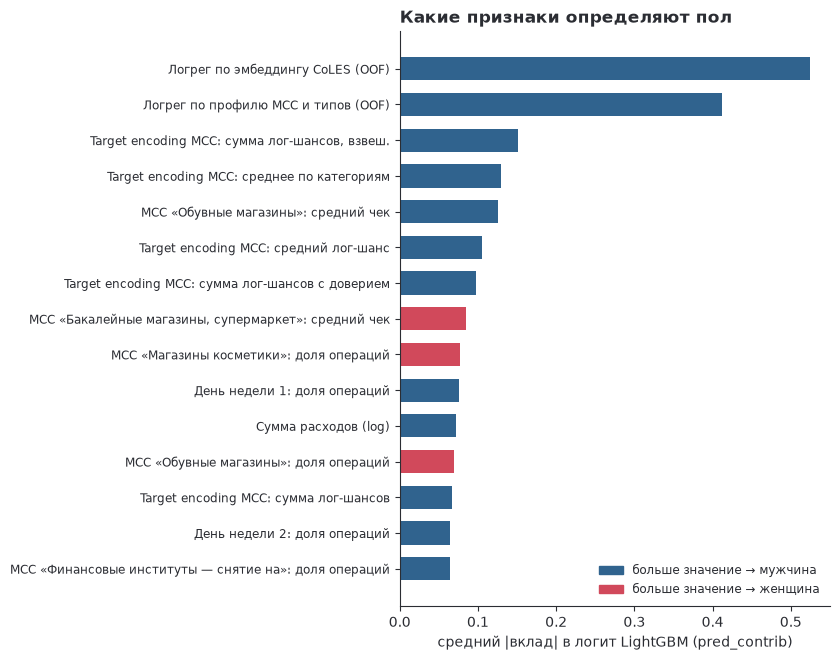

In [68]:
X_lab, y_lab = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
_, M_lab = cv.training_matrix(X_lab, y_lab, cfg)
contrib = model.gbm_contributions(M_lab)
shap = features.shap_summary(contrib, M_lab, top=15)
fig = plots.shap_summary(shap, names)

**Вывод.** Сильнее всего — сводные оценки профиля: логрег по поведенческому эмбеддингу и по профилю
покупок, target encoding MCC. Из отдельных предпочтений — обувь и косметика (к «женщине»), чек в
супермаркетах, объём расходов и снятие наличных (к «мужчине»), а также ритм недели.

### D.4 Карточка клиента подробно

Карточка собирается из транзакций без меток: **RFM** (давность, частота, деньги — с перцентилем среди
клиентов train); **предпочтения** — доли покупок по MCC (без снятия наличных и переводов) и личный lift
к среднему клиенту (только MCC, которыми пользуются ≥ 200 клиентов train); **привычки** — часы и дни недели
против среднего клиента, регулярность; **уровень трат** — средний чек, объём, доля крупных; **разнообразие** —
число категорий и концентрация (HHI). Пример — клиент train (без меток); ниже — ещё один клиент test (уверенно верно предсказанный мужчина).

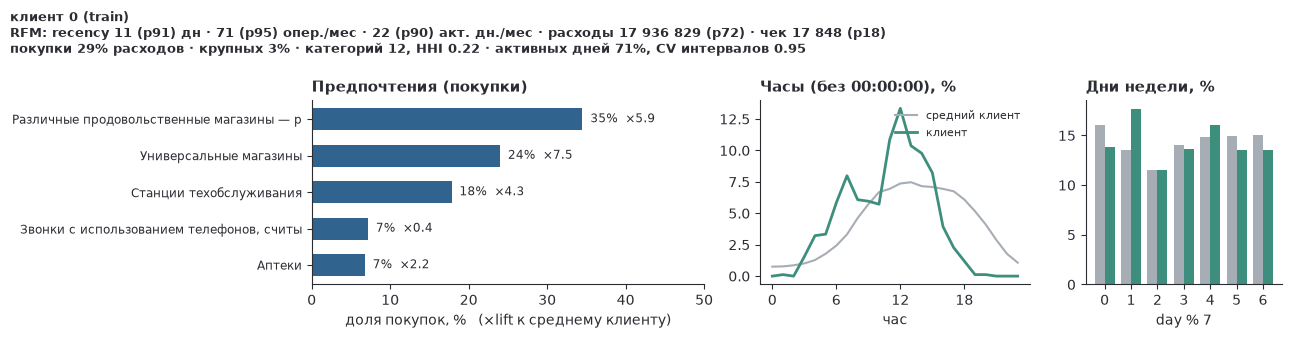

In [69]:
card = features.client_card(train_df, int(train_df["customer_id"].iloc[0]), ref)
fig = plots.client_card(card, ref, f"клиент {card['id']} (train)")

In [70]:
display(card["RFM"])
card["выше среднего"]

,значение,перцентиль среди train
"recency, дней",11.0,0.91
операций в месяц,71.3,0.95
активных дней в месяц,21.6,0.90
сумма расходов,17936829.3,0.72
средний чек,17847.6,0.18


,категория,доля покупок,lift
mcc_code,,,
8,Универсальные магазины,0.239993,7.521944
3,"Различные продовольственные магазины — рынки, ...",0.345007,5.943821
4,Станции техобслуживания,0.178255,4.267297


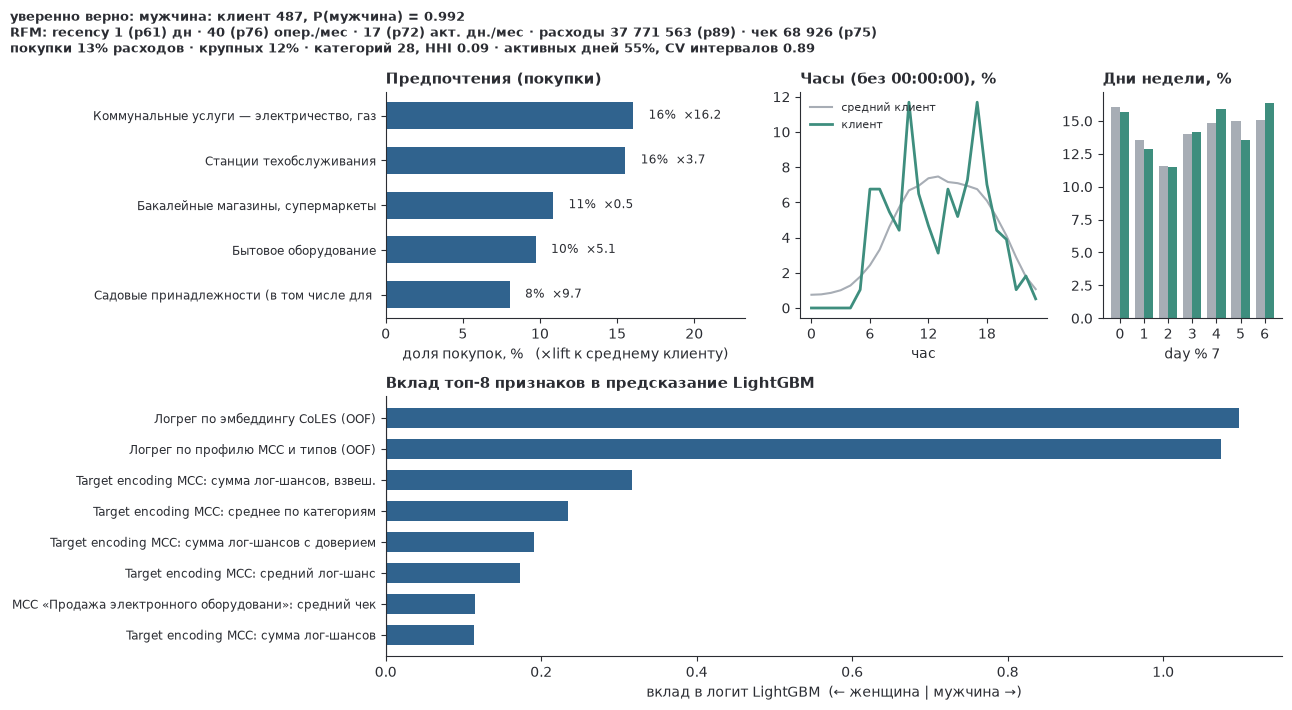

In [71]:
show_client("уверенно верно: мужчина")

**Вывод.** Автосервис и коммунальные платежи, крупный средний чек, большая доля наличных — все
модели дают > 98%.